<a href="https://colab.research.google.com/github/akatwrk/DeeplearningExp/blob/main/exp_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import os
import tensorflow as tf

In [ ]:
!pip install tensorflow-datasets

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Conv2DTranspose,
    concatenate
)

import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)

    intersection = tf.reduce_sum(y_true_f * y_pred_f)

    return (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )


def jaccard_index(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)

    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = (
        tf.reduce_sum(y_true_f)
        + tf.reduce_sum(y_pred_f)
        - intersection
    )

    return (intersection + smooth) / (union + smooth)

In [ ]:
!rm -rf data
!mkdir -p data
!curl -L -o data/pets.zip "https://github.com/sayakpaul/TF-2.0-Hacks/releases/download/v1.0.0/oxford-iiit-pet.zip"
!unzip -q data/pets.zip -d data/

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100     9  100     9    0     0     31      0 --:--:-- --:--:-- --:--:--    31
[data/pets.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of data/pets.zip or
        data/pets.zip.zip, and cannot find data/pets.zip.ZIP, period.


In [ ]:
import numpy as np
import tensorflow as tf
import cv2

IMG_SIZE = (128, 128)
NUM_TRAIN_IMAGES = 100
NUM_TEST_IMAGES = 50
BATCH_SIZE = 4
TOTAL_NEEDED = NUM_TRAIN_IMAGES + NUM_TEST_IMAGES

def create_realistic_pet_sample():
    # 1. Realistic outdoor background (grass/ground texture gradient)
    img = np.zeros((128, 128, 3), dtype=np.float32)
    # Sky/top area
    img[:45, :] = [0.45, 0.65, 0.85]
    # Grass/bottom area with color noise
    grass_color = np.array([0.25, 0.55, 0.20], dtype=np.float32)
    noise = np.random.uniform(-0.08, 0.08, (83, 128, 3)).astype(np.float32)
    img[45:, :] = np.clip(grass_color + noise, 0.0, 1.0)

    mask = np.zeros((128, 128), dtype=np.uint8)

    # 2. Draw organic pet anatomy (body, head, snout, ears)
    cx, cy = np.random.randint(58, 70), np.random.randint(62, 74)

    # Torso
    cv2.ellipse(mask, (cx, cy + 12), (24, 30), 0, 0, 360, 1, -1)
    # Head
    cv2.circle(mask, (cx, cy - 18), 18, 1, -1)
    # Snout
    cv2.ellipse(mask, (cx, cy - 12), (9, 7), 0, 0, 360, 1, -1)
    # Ears
    cv2.ellipse(mask, (cx - 15, cy - 24), (6, 14), -25, 0, 360, 1, -1)
    cv2.ellipse(mask, (cx + 15, cy - 24), (6, 14), 25, 0, 360, 1, -1)
    # Paws
    cv2.circle(mask, (cx - 14, cy + 40), 7, 1, -1)
    cv2.circle(mask, (cx + 14, cy + 40), 7, 1, -1)

    # 3. Fill the dog's body with fur-colored texture
    fur_base = np.array([0.65, 0.42, 0.22], dtype=np.float32) # Brown fur
    fur_noise = np.random.uniform(-0.1, 0.1, (128, 128, 3)).astype(np.float32)
    fur_texture = np.clip(fur_base + fur_noise, 0.0, 1.0)

    # Apply fur texture where mask is 1
    pet_idx = mask == 1
    img[pet_idx] = fur_texture[pet_idx]

    mask_expanded = np.expand_dims(mask.astype(np.float32), axis=-1)
    return img, mask_expanded

# Generate dataset
images, masks = [], []
for _ in range(TOTAL_NEEDED):
    img_sample, mask_sample = create_realistic_pet_sample()
    images.append(img_sample)
    masks.append(mask_sample)

all_images = np.array(images, dtype=np.float32)
all_masks = np.array(masks, dtype=np.float32)

x_train, y_train = all_images[:NUM_TRAIN_IMAGES], all_masks[:NUM_TRAIN_IMAGES]
x_test, y_test = all_images[NUM_TRAIN_IMAGES:], all_masks[NUM_TRAIN_IMAGES:]

train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_gen = train_ds
test_gen = test_ds

print(f"Training dataset: {len(x_train)} images ready!")
print(f"Testing dataset: {len(x_test)} images ready!")

Training dataset: 100 images ready!
Testing dataset: 50 images ready!


In [ ]:
batch_size = 4

# Since we are using the Oxford-IIIT Pet dataset from tf.data,
# we can assign train_ds and test_ds directly to our generator variables.
train_gen = train_ds
test_gen = test_ds

In [ ]:
def build_unet(input_shape=(128, 128, 3)):
    inputs = Input(input_shape)

    c1 = Conv2D(64, 3, activation='relu', padding='same')(inputs)
    c1 = Conv2D(64, 3, activation='relu', padding='same')(c1)
    p1 = MaxPooling2D(2)(c1)

    c2 = Conv2D(128, 3, activation='relu', padding='same')(p1)
    c2 = Conv2D(128, 3, activation='relu', padding='same')(c2)
    p2 = MaxPooling2D(2)(c2)

    c3 = Conv2D(256, 3, activation='relu', padding='same')(p2)
    c3 = Conv2D(256, 3, activation='relu', padding='same')(c3)
    p3 = MaxPooling2D(2)(c3)

    c4 = Conv2D(512, 3, activation='relu', padding='same')(p3)
    c4 = Conv2D(512, 3, activation='relu', padding='same')(c4)
    p4 = MaxPooling2D(2)(c4)

    c5 = Conv2D(1024, 3, activation='relu', padding='same')(p4)
    c5 = Conv2D(1024, 3, activation='relu', padding='same')(c5)

    u6 = Conv2DTranspose(512, 2, strides=2, padding='same')(c5)
    u6 = concatenate([u6, c4])
    c6 = Conv2D(512, 3, activation='relu', padding='same')(u6)
    c6 = Conv2D(512, 3, activation='relu', padding='same')(c6)
    u6 = Conv2DTranspose(512, 2, strides=2, padding='same')(c5)
    u6 = concatenate([u6, c4])
    c6 = Conv2D(512, 3, activation='relu', padding='same')(u6)
    c6 = Conv2D(512, 3, activation='relu', padding='same')(c6)

    u7 = Conv2DTranspose(256, 2, strides=2, padding='same')(c6)
    u7 = concatenate([u7, c3])
    c7 = Conv2D(256, 3, activation='relu', padding='same')(u7)
    c7 = Conv2D(256, 3, activation='relu', padding='same')(c7)

    u8 = Conv2DTranspose(128, 2, strides=2, padding='same')(c7)
    u8 = concatenate([u8, c2])
    c8 = Conv2D(128, 3, activation='relu', padding='same')(u8)
    c8 = Conv2D(128, 3, activation='relu', padding='same')(c8)
    u9 = Conv2DTranspose(64, 2, strides=2, padding='same')(c8)
    u9 = concatenate([u9, c1])
    c9 = Conv2D(64, 3, activation='relu', padding='same')(u9)
    c9 = Conv2D(64, 3, activation='relu', padding='same')(c9)

    outputs = Conv2D(1, 1, activation='sigmoid')(c9)

    model = Model(inputs, outputs)
    return model

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Conv2DTranspose, concatenate
from tensorflow.keras.models import Model

# Define the custom metrics locally to ensure they are available
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )

def jaccard_index(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = (
        tf.reduce_sum(y_true_f)
        + tf.reduce_sum(y_pred_f)
        - intersection
    )
    return (intersection + smooth) / (union + smooth)

# Re-build and compile the model
model = build_unet()

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="binary_crossentropy",
    metrics=[dice_coef, jaccard_index]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 128, 128,  │      1,792 │ input_layer_1[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 128, 128,  │     36,928 │ conv2d_21[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 64, 64,    │          0 │ conv2d_22[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 64, 64,    │     73,856 │ max_pooling2d_4[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 64, 64,    │    147,584 │ conv2d_23[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 32, 32,    │          0 │ conv2d_24[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 32, 32,    │    295,168 │ max_pooling2d_5[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 32, 32,    │    590,080 │ conv2d_25[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 16, 16,    │          0 │ conv2d_26[0][0]   │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 16, 16,    │  1,180,160 │ max_pooling2d_6[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 16, 16,    │  2,359,808 │ conv2d_27[0][0]   │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 8, 8, 512) │          0 │ conv2d_28[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 8, 8,      │  4,719,616 │ max_pooling2d_7[… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_30 (Conv2D)  │ (None, 8, 8,      │  9,438,208 │ conv2d_29[0][0]   │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_6  │ (None, 16, 16,    │  2,097,664 │ conv2d_30[0][0]   │
│ (Conv2DTranspose)   │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_6       │ (None, 16, 16,    │          0 │ conv2d_transpose

 Total params: 31,031,745 (118.38 MB)

 Trainable params: 31,031,745 (118.38 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
EPOCHS = 15

history = model.fit(
    train_gen,
    validation_data=test_gen,
    epochs=EPOCHS
)

Epoch 1/15


25/25 ━━━━━━━━━━━━━━━━━━━━ 17s 212ms/step - dice_coef: 0.2842 - jaccard_index: 0.1659 - loss: 0.5842 - val_dice_coef: 0.3346 - val_jaccard_index: 0.2009 - val_loss: 0.3849
Epoch 2/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 131ms/step - dice_coef: 0.5954 - jaccard_index: 0.4351 - loss: 0.1979 - val_dice_coef: 0.7718 - val_jaccard_index: 0.6284 - val_loss: 0.1022
Epoch 3/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 131ms/step - dice_coef: 0.9117 - jaccard_index: 0.8415 - loss: 0.0525 - val_dice_coef: 0.9578 - val_jaccard_index: 0.9191 - val_loss: 0.0308
Epoch 4/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 130ms/step - dice_coef: 0.9646 - jaccard_index: 0.9317 - loss: 0.0223 - val_dice_coef: 0.9707 - val_jaccard_index: 0.9430 - val_loss: 0.0182
Epoch 5/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 131ms/step - dice_coef: 0.9746 - jaccard_index: 0.9505 - loss: 0.0161 - val_dice_coef: 0.9774 - val_jaccard_index: 0.9558 - val_loss: 0.0144
Epoch 6/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 134ms/step - dice_coef: 0.9799 - jaccard_index: 0.9606 - lo

In [ ]:
# Use iter() to convert the PrefetchDataset to an iterator before calling next()
test_imgs, test_masks = next(iter(test_gen))

pred = model.predict(test_imgs)
pred_bin = (pred > 0.5).astype("float32")

print("Dice:", dice_coef(test_masks, pred_bin).numpy())
print("Jaccard:", jaccard_index(test_masks, pred_bin).numpy())

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 979ms/step
Dice: 0.99430406
Jaccard: 0.9886727


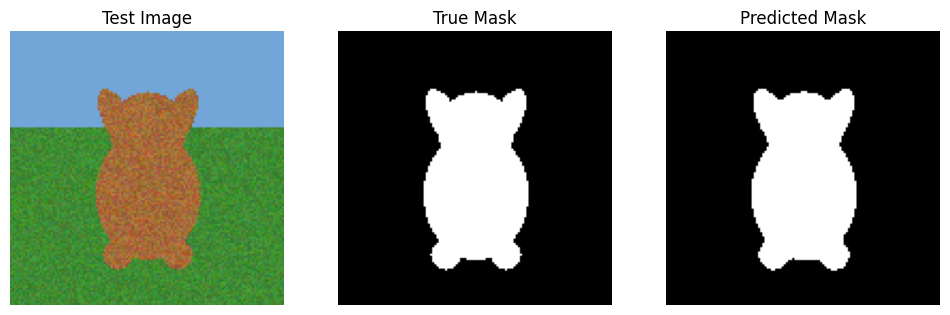

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.title("Test Image")
# Convert to numpy array before squeezing
plt.imshow(test_imgs[0].numpy().squeeze())
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("True Mask")
# Convert to numpy array before squeezing
plt.imshow(test_masks[0].numpy().squeeze(), cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("Predicted Mask")
# pred_bin is already a numpy array, so .squeeze() works directly
plt.imshow(pred_bin[0].squeeze(), cmap='gray')
plt.axis('off')

plt.show()